<div align="center">

#### **PEMBUATAN RECIPE**

#### **_Synthetic Groundwater Transport Reference Implementation_**


#### **KECERDASAN ARTIFISIAL GEOFISIKA**



#### **SERILIA ABUNG**

#### **H061241034**

#### **DEPARTEMEN GEOFISIKA**

#### **FAKULTAS MATEMATIKA DAN ILMU PENGETAHUAN ALAM**

#### **UNIVERSITAS HASANUDDIN**

![Screenshot 2026-10-21 095648.png](<attachment:Screenshot 2026-10-21 095648.png>)
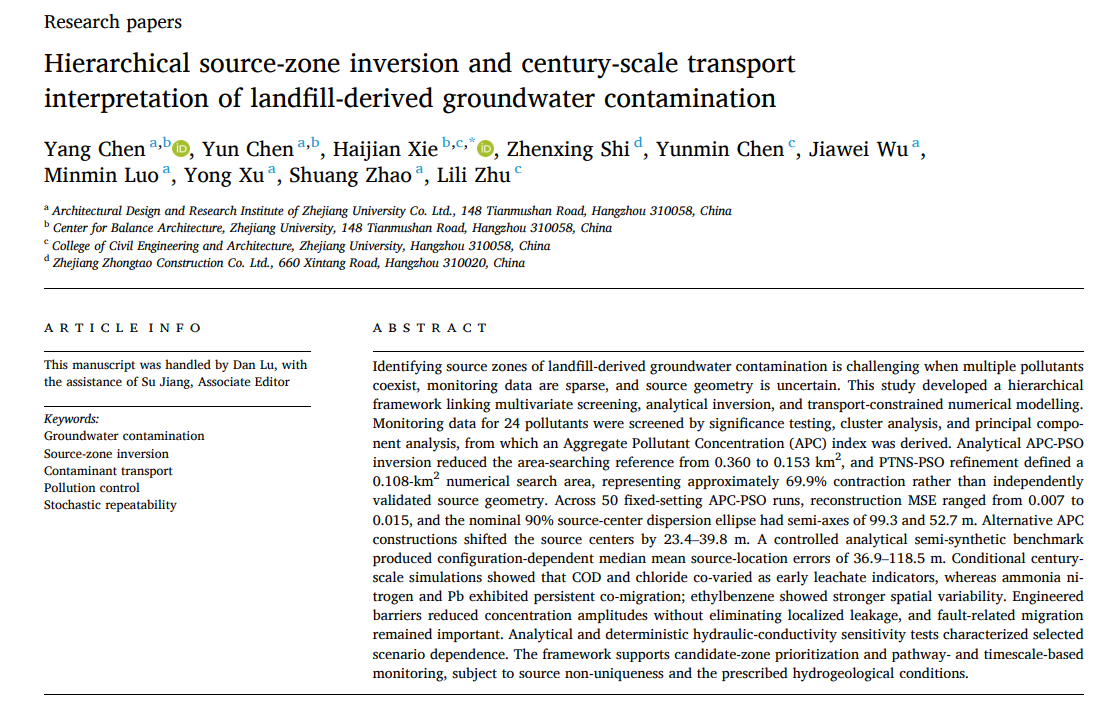

Courant adveksi = 0.0050
Bilangan dispersi = 0.0500
Massa awal relatif : 0.531736
Massa akhir relatif: 0.531736
Perubahan massa (%) : 0.000000


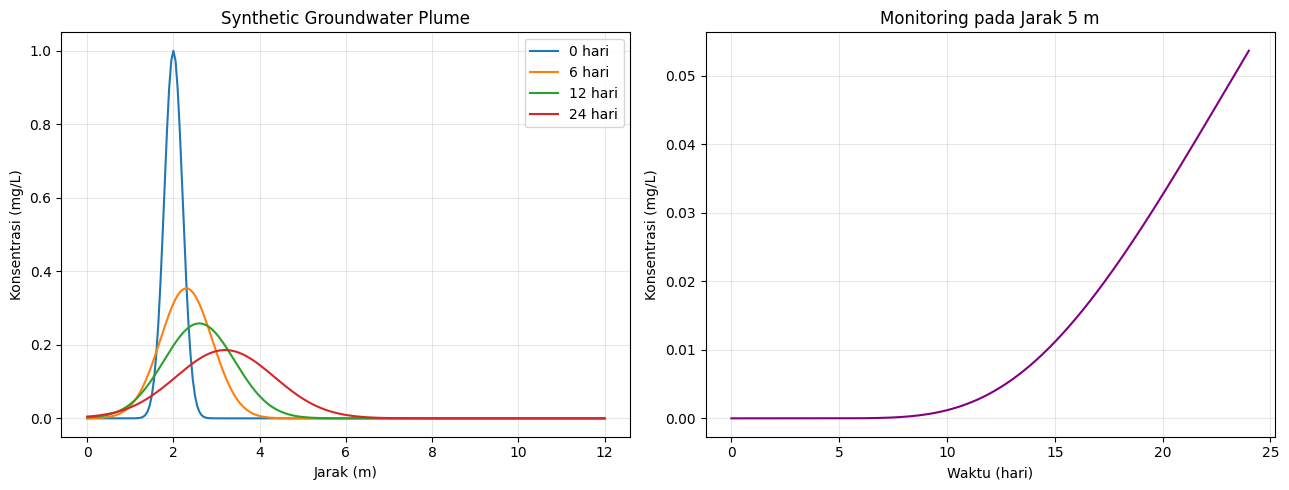

In [1]:

import numpy as np
import matplotlib.pyplot as plt

# ==================================================
# 1. PARAMETER MODEL
# ==================================================
L = 12.0             # Panjang domain (m)
dx = 0.05            # Ukuran grid (m)
v = 0.05             # Kecepatan adveksi efektif (m/hari)
D = 0.025            # Koefisien dispersi (m^2/hari)
T = 24.0             # Durasi simulasi (hari)
dt = 0.005           # Interval waktu (hari)

# Pemeriksaan kestabilan numerik
cfl_adv = abs(v) * dt / dx
cfl_disp = D * dt / dx**2

print(f"Courant adveksi = {cfl_adv:.4f}")
print(f"Bilangan dispersi = {cfl_disp:.4f}")

if cfl_adv + 2 * cfl_disp > 1:
    raise ValueError(
        "Parameter tidak memenuhi batas kestabilan eksplisit."
    )

# Grid spasial dan temporal
x = np.arange(0, L + dx / 2, dx)
nx = len(x)
nt = int(round(T / dt)) + 1
time = np.arange(nt) * dt

# ==================================================
# 2. KONDISI AWAL: PLUME KONTAMINAN
# ==================================================
C0 = np.exp(-((x - 2.0) / 0.30)**2)

# Konsentrasi awal maksimum = 1 mg/L
C = C0.copy()

# Snapshot yang akan direkam
snapshot_days = [0, 6, 12, 24]
snapshots = {0: C.copy()}

# Titik pemantauan pada jarak 5 meter
monitor_x = 5.0
monitor_idx = int(round(monitor_x / dx))

monitor_time = [0.0]
monitor_concentration = [C[monitor_idx]]

# ==================================================
# 3. SOLVER ADVEKSI-DISPERSI KONSERVATIF
# ==================================================
for n in range(1, nt):

    # Fluks pada sisi antar-grid:
    # J = v*C - D*dC/dx
    # Adveksi menggunakan skema upwind.

    J = np.zeros(nx + 1)

    # Fluks internal antar-sel
    if v >= 0:
        C_upwind = C[:-1]
    else:
        C_upwind = C[1:]

    advective_flux = v * C_upwind
    dispersive_flux = -D * (C[1:] - C[:-1]) / dx

    J[1:-1] = advective_flux + dispersive_flux

    # Fluks batas kiri dan kanan tetap nol
    J[0] = 0.0
    J[-1] = 0.0

    # Pembaruan konsentrasi berdasarkan keseimbangan fluks
    C_new = C - (dt / dx) * (J[1:] - J[:-1])

    # Koreksi kecil untuk nilai negatif akibat pembulatan
    C_new = np.maximum(C_new, 0.0)

    C = C_new

    current_time = n * dt

    # Simpan data konsentrasi di titik monitoring
    monitor_time.append(current_time)
    monitor_concentration.append(C[monitor_idx])

    # Simpan snapshot pada waktu yang ditentukan
    for day in snapshot_days:
        if day not in snapshots and np.isclose(
            current_time, day, atol=dt / 2
        ):
            snapshots[day] = C.copy()

# ==================================================
# 4. PEMERIKSAAN KONSERVASI MASSA
# ==================================================
mass_initial = np.sum(C0) * dx
mass_final = np.sum(C) * dx

mass_error = abs(mass_final - mass_initial) / mass_initial * 100

print(f"Massa awal relatif : {mass_initial:.6f}")
print(f"Massa akhir relatif: {mass_final:.6f}")
print(f"Perubahan massa (%) : {mass_error:.6f}")

# ==================================================
# 5. VISUALISASI HASIL
# ==================================================
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

# Grafik snapshot plume
for day in snapshot_days:
    axes[0].plot(
        x, snapshots[day],
        label=f"{day} hari"
    )

axes[0].set_title("Synthetic Groundwater Plume")
axes[0].set_xlabel("Jarak (m)")
axes[0].set_ylabel("Konsentrasi (mg/L)")
axes[0].grid(True, alpha=0.3)
axes[0].legend()

# Grafik monitoring point
axes[1].plot(
    monitor_time,
    monitor_concentration,
    color="purple"
)

axes[1].set_title("Monitoring pada Jarak 5 m")
axes[1].set_xlabel("Waktu (hari)")
axes[1].set_ylabel("Konsentrasi (mg/L)")
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()


**Analisis Hasil**

Grafik pertama: Synthetic Groundwater Plume. Grafik pertama menunjukkan perubahan distribusi konsentrasi zat terlarut sepanjang domain selama 24 hari. Pada hari ke-0, konsentrasi terkonsentrasi di sekitar sumber awal pada posisi 2 meter. Seiring bertambahnya waktu, proses adveksi menggeser pusat plume ke arah aliran, sedangkan dispersi menyebabkan distribusi konsentrasi menjadi lebih lebar dan puncak konsentrasinya cenderung menurun. Perubahan tersebut menunjukkan bahwa zat terlarut tidak hanya berpindah mengikuti aliran air tanah, tetapi juga menyebar ke wilayah di sekitarnya. Karena model menggunakan medium homogen dan parameter konstan, pola plume yang dihasilkan relatif sederhana dibandingkan kondisi lapangan yang memiliki variasi permeabilitas dan struktur geologi.

Grafik kedua: Monitoring pada Jarak 5 meter. Grafik kedua memperlihatkan perubahan konsentrasi terhadap waktu pada titik pemantauan yang berada 5 meter dari awal domain. Pada awal simulasi, konsentrasi di titik tersebut diperkirakan sangat kecil karena plume masih terkonsentrasi di sekitar posisi 2 meter. Ketika plume bergerak dan menyebar mendekati titik pemantauan, konsentrasi akan meningkat. Besarnya konsentrasi yang tercatat bergantung pada kecepatan transportasi, koefisien dispersi, bentuk distribusi awal, dan jarak titik pemantauan terhadap plume. Grafik ini dapat digunakan untuk memperkirakan waktu kedatangan kontaminan dan memahami perubahan konsentrasi yang mungkin teramati pada sumur pemantauan.

Pemeriksaan konservasi massa. Nilai massa awal dan massa akhir yang ditampilkan oleh kode digunakan untuk mengevaluasi perubahan massa relatif selama simulasi. Dalam model satu dimensi dengan fluks nol pada kedua batas, jumlah konsentrasi yang diintegrasikan terhadap panjang domain seharusnya tetap mendekati nilai awal. Apabila perbedaan massa relatif sangat kecil, hasil tersebut menunjukkan bahwa model mempertahankan massa dengan baik. Namun, kode menggunakan pemotongan nilai konsentrasi negatif menjadi nol sebagai koreksi numerik; tindakan ini berpotensi menambah massa secara artifisial apabila nilai negatif muncul. Oleh karena itu, nilai perubahan massa tetap perlu diperiksa dan sebaiknya tidak langsung dianggap nol.